# Baseline de vídeo: personas, caras y tiempo en pantalla

**Reto Mujeres por la IA Abierta · Sesión de visión por computador**

Este notebook es el *pipeline* base que aparece en las slides (bloque 8). **Es un punto de partida, no una solución**: es deliberadamente simple y tiene errores conocidos. El reto consiste en mejorarlo.

| Paso | Qué hace | Herramienta |
|---|---|---|
| 1 | Detectar personas y seguirlas en el tiempo (cada persona recibe un número de *track*) | YOLO + ByteTrack |
| 2 | Detectar caras, estimar el **género percibido** y votar entre fotogramas para cada *track* | InsightFace |
| 3 | Calcular medidas por persona (tiempo en pantalla, tamaño, centralidad) y el % por grupo | pandas |

**Antes de ejecutar:** en Colab, *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU*. También funciona en CPU, pero más despacio. Después, *Ejecutar todo*.

**Avisos importantes**
- Los modelos de cara **no ven la identidad de género**: predicen cómo se *percibe* una cara según las etiquetas (binarias) de sus datos de entrenamiento. Tratad la salida como una estimación incierta y mantened una categoría `unknown`.
- Los modelos preentrenados de InsightFace tienen **licencia de uso solo para investigación no comercial**. Ultralytics YOLO tiene licencia AGPL-3.0.
- Vídeo de ejemplo: *Intel IoT DevKit sample videos*, `face-demographics-walking-and-pause.mp4`, licencia **CC BY 4.0**.

## 0. El vídeo

Descargamos el vídeo de ejemplo y lo mostramos. Para usar un vídeo vuestro, subidlo al panel de archivos de la izquierda y cambiad `VIDEO`.

In [1]:
import cv2, subprocess, urllib.request
from IPython.display import Video, display

VIDEO = "videos/robot_social_CSIC.mp4"     # <- cambiad aquí para usar otro vídeo
# VIDEO = "clip_quanta.mp4"

if VIDEO == "face-demographics-walking-and-pause.mp4":
    urllib.request.urlretrieve("https://raw.githubusercontent.com/intel-iot-devkit/sample-videos/master/face-demographics-walking-and-pause.mp4", VIDEO)

cap = cv2.VideoCapture(VIDEO)
FPS, W, H = cap.get(cv2.CAP_PROP_FPS), int(cap.get(3)), int(cap.get(4))
print(f"{FPS:.0f} fps, {W}x{H}, {cap.get(cv2.CAP_PROP_FRAME_COUNT) / FPS:.0f} s")

# convert to H.264 so that the browser can play it
subprocess.run(f"ffmpeg -y -loglevel error -i {VIDEO} -vcodec libx264 -pix_fmt yuv420p input_h264.mp4", shell=True)
display(Video("input_h264.mp4", embed=True, width=640))

25 fps, 640x360, 149 s


## 1. Paso 1: detectar y seguir personas (YOLO + ByteTrack)

No analizamos todos los fotogramas: con `STRIDE = 4` nos quedamos con 1 de cada 4 (3 por segundo en este vídeo de 12 fps).

In [4]:
import pandas as pd
from ultralytics import YOLO

STRIDE = 4
model = YOLO("yolo11m.pt")                     # pretrained on COCO: class 0 = person
results = model.track(VIDEO, classes=[0], tracker="bytetrack.yaml",
                      vid_stride=STRIDE, stream=True, verbose=False)
rows = []
for f, r in enumerate(results):              # f = index of the analysed frame
    for b in r.boxes:
        if b.id is None: continue
        x1, y1, x2, y2 = b.xyxy[0].tolist()
        rows.append(dict(frame=f, track=int(b.id), conf=float(b.conf),
                         x1=x1, y1=y1, x2=x2, y2=y2))
df = pd.DataFrame(rows)
print(len(df), "detections,", df.track.nunique(), "tracks")
df.head()

880 detections, 14 tracks


,frame,track,conf,x1,y1,x2,y2
0,0,1,0.928765,187.679001,1.316956,639.128967,353.986633
1,1,1,0.938627,182.748825,1.105495,635.645752,354.775818
2,2,1,0.886833,176.515564,1.282379,629.857544,354.822968
3,3,1,0.916755,173.952805,1.223444,628.127930,354.787628
4,4,1,0.930526,174.523804,1.366487,628.990967,354.479309


### 1.1 Empezar un *track* nuevo en cada corte de plano

En un vídeo editado, cuando cambia el plano y aparece otra persona en una posición parecida, ByteTrack a veces le da el mismo número de *track* que a la persona del plano anterior. Ese *track* mezcla a dos personas y su voto de género sale `unknown` o directamente mal.

El arreglo: detectamos los cortes de plano con [PySceneDetect](https://www.scenedetect.com/) (código de su *Quick Start*) y partimos cada *track* en uno nuevo por plano. Todo lo que viene después (el paso 2 original y la sección 6 con MiVOLO) usa estos *tracks* ya corregidos.

In [ ]:
import numpy as np
from scenedetect import detect, ContentDetector

# Ejemplo del Quick Start de PySceneDetect: detecta los planos del vídeo
scene_list = detect(VIDEO, ContentDetector())
cuts = [scene[0].frame_num for scene in scene_list[1:]]          # primer fotograma de cada plano (salvo el primero)
print(len(scene_list), "planos; cortes en", [f"{c / FPS:.1f}s" for c in cuts])

# Plano de cada detección. Con vid_stride, YOLO analizó los fotogramas STRIDE-1, 2*STRIDE-1... del vídeo
df["shot"] = np.searchsorted(cuts, df.frame * STRIDE + STRIDE - 1, side="right")
# Un track nuevo por cada combinación (track de ByteTrack, plano); guardamos el número original por si acaso
df["track_bytetrack"] = df.track
df["track"] = df.groupby(["track_bytetrack", "shot"]).ngroup() + 1
print(df.track_bytetrack.nunique(), "tracks de ByteTrack ->", df.track.nunique(), "tracks tras partir por planos")

27 planos; cortes en ['10.7s', '17.7s', '23.0s', '26.2s', '33.3s', '34.8s', '38.6s', '43.1s', '44.5s', '54.9s', '57.4s', '59.5s', '67.0s', '70.0s', '73.0s', '78.4s', '86.4s', '88.8s', '93.2s', '94.9s', '100.6s', '109.4s', '112.6s', '123.6s', '131.7s', '144.0s']
14 tracks de ByteTrack -> 30 tracks tras partir por planos


### 1.2 Descartar *tracks* cortos o dudosos

En los primeros planos, YOLO a veces detecta como "persona" una mano, un brazo o un hombro. Esos *tracks* suelen ser **cortos** y tener **poca confianza**, así que hacemos lo habitual en los pipelines de seguimiento: quedarnos solo con los *tracks* que duran al menos `MIN_SECONDS` y cuya confianza media es al menos `MIN_CONF`. Si en vuestro vídeo se pierde alguna persona real, bajad los umbrales.

In [ ]:
MIN_SECONDS = 1.0     # duración mínima del track en pantalla
MIN_CONF = 0.8        # confianza media mínima de YOLO en el track

stats = df.groupby("track").agg(frames=("frame", "nunique"), conf=("conf", "mean"))
stats["seconds"] = stats.frames / (FPS / STRIDE)
keep = stats.index[(stats.seconds >= MIN_SECONDS) & (stats.conf >= MIN_CONF)]

print(f"Descartamos {len(stats) - len(keep)} de {len(stats)} tracks:")
display(stats.drop(keep).round(2))
df = df[df.track.isin(keep)].reset_index(drop=True)

Descartamos 6 de 30 tracks:


,frames,conf,seconds
track,,,
7,6,0.87,0.96
9,3,0.42,0.48
16,10,0.79,1.60
18,6,0.76,0.96
21,18,0.59,2.88
23,8,0.58,1.28


## 2. Paso 2: caras y género percibido por *track* (InsightFace)

Para cada fotograma analizado detectamos las caras, asignamos cada cara a la caja de persona que la contiene y guardamos el voto (`F` / `M`). Al final, cada *track* recibe una etiqueta solo si hay al menos 2 caras y el 80 % de los votos coincide; si no, `unknown`.

In [ ]:
from collections import Counter
from insightface.app import FaceAnalysis

app = FaceAnalysis(name="buffalo_l", providers=["CUDAExecutionProvider", "CPUExecutionProvider"])
app.prepare(ctx_id=0, det_size=(640, 640))

votes = {t: [] for t in df.track.unique()}
faces_per_frame = {}
for f in sorted(df.frame.unique()):
    cap.set(cv2.CAP_PROP_POS_FRAMES, f * STRIDE); ok, frame = cap.read()
    if not ok: continue
    people = df[df.frame == f]
    faces_per_frame[f] = []
    for fc in app.get(frame):                # frame in BGR, as read by OpenCV
        faces_per_frame[f].append((fc.bbox, fc.sex, int(fc.age)))
        cx, cy = (fc.bbox[0] + fc.bbox[2]) / 2, (fc.bbox[1] + fc.bbox[3]) / 2
        inside = people[(people.x1 <= cx) & (cx <= people.x2) & (people.y1 <= cy) & (cy <= people.y2)]
        if len(inside):                      # smallest person box that contains the face
            t = inside.loc[(inside.x2 - inside.x1).idxmin(), "track"]
            votes[t].append(fc.sex)

def vote(v, min_faces=2, min_agree=0.8):
    if len(v) < min_faces: return "unknown"
    label, n = Counter(v).most_common(1)[0]
    return label if n / len(v) >= min_agree else "unknown"

track_gender = {int(t): vote(v) for t, v in votes.items()}
for t, v in votes.items():
    print(f"track {t}: votes {dict(Counter(v))} -> {track_gender[int(t)]}")

/home/rjvillen/projects/attention-is-all-she-needs/.venv/lib/python3.13/site-packages/onnxruntime/capi/onnxruntime_inference_collection.py:197: UserWarning: Specified provider 'CUDAExecutionProvider' is not in available provider names.Available providers: 'AzureExecutionProvider, CPUExecutionProvider'
  warnings.warn(
/home/rjvillen/projects/attention-is-all-she-needs/.venv/lib/python3.13/site-packages/insightface/utils/face_align.py:23: FutureWarning: `estimate` is deprecated since version 0.26 and will be removed in version 2.2. Please use `SimilarityTransform.from_estimate` class constructor instead.
  tform.estimate(lmk, dst)


track 1: votes {} -> unknown
track 2: votes {'M': 43} -> M
track 3: votes {'M': 19} -> M
track 4: votes {'F': 44} -> F
track 5: votes {'M': 43} -> M
track 6: votes {'M': 9, 'F': 1} -> M
track 8: votes {} -> unknown
track 10: votes {'M': 64} -> M
track 11: votes {'M': 5, 'F': 10} -> unknown
track 17: votes {'M': 14} -> M
track 19: votes {'F': 4, 'M': 10} -> unknown
track 12: votes {'M': 46} -> M
track 13: votes {'M': 7, 'F': 12} -> unknown
track 20: votes {'M': 18} -> M
track 22: votes {} -> unknown
track 14: votes {'M': 32} -> M
track 15: votes {'M': 51} -> M
track 24: votes {'F': 10, 'M': 17} -> unknown
track 25: votes {'M': 10} -> M
track 26: votes {'M': 35} -> M
track 27: votes {'M': 1} -> unknown
track 28: votes {'M': 18} -> M
track 29: votes {'M': 1, 'F': 68} -> F
track 30: votes {'F': 76} -> F


## 3. Paso 3: de los *tracks* a las medidas

In [ ]:
FPS_SAMPLED = FPS / STRIDE
df["area"] = (df.x2 - df.x1) * (df.y2 - df.y1) / (W * H)     # fraction of the frame
df["cx"]   = (df.x1 + df.x2) / 2 / W                          # horizontal centre, 0..1

per_track = df.groupby("track").agg(
    frames=("frame", "nunique"), area=("area", "mean"),
    centrality=("cx", lambda c: 1 - 2 * (c - 0.5).abs().mean()))
per_track["screen_time_s"] = per_track.frames / FPS_SAMPLED
per_track["gender"] = per_track.index.map(track_gender)
display(per_track.round(2))

share = per_track.groupby("gender").screen_time_s.sum()
print("% of screen time by predicted label:")
print((100 * share / share.sum()).round(1))

,frames,area,centrality,screen_time_s,gender
track,,,,,
1,67,0.69,0.72,10.72,unknown
2,43,0.55,0.90,6.88,M
3,19,0.39,0.95,3.04,M
4,44,0.17,0.81,7.04,F
5,43,0.40,0.67,6.88,M
6,9,0.48,0.90,1.44,M
8,19,0.86,0.88,3.04,unknown
10,64,0.36,0.75,10.24,M
11,15,0.48,0.55,2.40,unknown


% of screen time by predicted label:
gender
F          22.8
M          48.7
unknown    28.5
Name: screen_time_s, dtype: float64


## 4. Ver el resultado: vídeo anotado

Dibujamos sobre cada fotograma analizado la caja de cada persona (morado = `F`, azul = `M`, gris = `unknown`) y la cara con lo que predice el modelo en *ese* fotograma. Fijaos en cuándo la predicción de la cara cambia de un fotograma a otro.

In [ ]:
COL = {"F": (161, 86, 99), "M": (176, 143, 46), "unknown": (150, 150, 150)}   # BGR
vw = cv2.VideoWriter("annot_raw.mp4", cv2.VideoWriter_fourcc(*"mp4v"), FPS_SAMPLED, (W, H))
for f in sorted(df.frame.unique()):
    cap.set(cv2.CAP_PROP_POS_FRAMES, f * STRIDE); ok, frame = cap.read()
    for _, r in df[df.frame == f].iterrows():
        g = track_gender[int(r.track)]; c = COL[g]
        cv2.rectangle(frame, (int(r.x1), int(r.y1)), (int(r.x2), int(r.y2)), c, 3)
        lab = f"person {int(r.track)} | {g}"
        (tw, th), _ = cv2.getTextSize(lab, cv2.FONT_HERSHEY_SIMPLEX, 0.6, 2)
        cv2.rectangle(frame, (int(r.x1), int(r.y1)), (int(r.x1) + tw + 10, int(r.y1) + th + 12), c, -1)
        cv2.putText(frame, lab, (int(r.x1) + 5, int(r.y1) + th + 5), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2)
    for bb, sex, age in faces_per_frame.get(f, []):
        x1, y1, x2, y2 = map(int, bb)
        cv2.rectangle(frame, (x1, y1), (x2, y2), (255, 255, 255), 2)
        cv2.putText(frame, f"face {sex} ~{age}y", (x1, y2 + 18), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)
    cv2.putText(frame, f"t = {f * STRIDE / FPS:4.1f} s", (12, H - 12), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)
    vw.write(frame)
vw.release()
subprocess.run("ffmpeg -y -loglevel error -i annot_raw.mp4 -vcodec libx264 -pix_fmt yuv420p annotated.mp4", shell=True)
display(Video("annotated.mp4", embed=True, width=640))

## 5. Gráficos

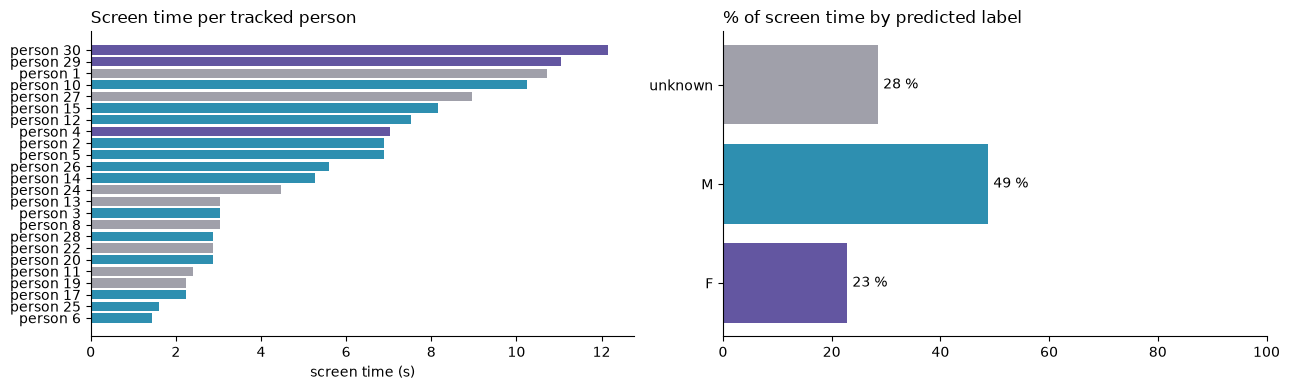

In [ ]:
import matplotlib.pyplot as plt
P = {"F": "#6356A1", "M": "#2E8FB0", "unknown": "#A0A0AA"}
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
pt = per_track.sort_values("screen_time_s")
a1.barh([f"person {t}" for t in pt.index], pt.screen_time_s, color=[P[g] for g in pt.gender])
a1.set_xlabel("screen time (s)"); a1.set_title("Screen time per tracked person", loc="left")
sh = 100 * share / share.sum()
a2.barh(list(sh.index), sh.values, color=[P[g] for g in sh.index])
for y, v in enumerate(sh.values): a2.text(v + 1, y, f"{v:.0f} %", va="center")
a2.set_xlim(0, 100); a2.set_title("% of screen time by predicted label", loc="left")
for a in (a1, a2):
    for s in ["top", "right"]: a.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

## ¿Y ahora qué?

Mirad el vídeo anotado y comparad con lo que veis vosotras: ¿cuántas mujeres y cuántos hombres aparecen? ¿Coincide con el resultado?

Algunas ideas para mejorar el *baseline*:
- **Definición:** ¿qué significa "protagonista"? Tiempo en pantalla, tamaño, centralidad, planos, mirada a cámara, si habla…
- **Percepción:** caras pequeñas o de perfil, unir *tracks* de la misma persona (re-identificación), detección de cortes de plano.
- **Multimodal:** combinar con el audio (quién habla) y con el texto (quién es nombrado, rótulos).
- **Incertidumbre y sesgo:** medir los errores por subgrupo; no esconder la categoría `unknown`.
- **Evaluación:** anotad a mano una muestra de *vuestro* contenido y medid el error de la medida final.

## 6. El mismo pipeline con un modelo mejor: MiVOLO v2

Repetimos los pasos 2, 3 y 4 cambiando **solo el modelo de género percibido**: en vez del `genderage` de InsightFace usamos [MiVOLO v2](https://huggingface.co/iitolstykh/mivolo_v2) (licencia Apache-2.0). MiVOLO mira la cara **y el cuerpo** de cada persona, así que también puede predecir cuando la cara se ve mal o no se ve.

Todo lo demás es igual que antes: los *tracks* de YOLO (paso 1), el detector de caras de InsightFace (`app`, paso 2) y la votación `vote()`. **Antes, ejecutad las secciones 0 a 3.**

In [ ]:
import torch
from transformers import AutoModelForImageClassification, AutoConfig, AutoImageProcessor

# Carga del modelo copiada del "Quick start" de la model card: https://huggingface.co/iitolstykh/mivolo_v2
device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32      # fp16 en GPU (como la model card), fp32 en CPU

config = AutoConfig.from_pretrained("iitolstykh/mivolo_v2", trust_remote_code=True)
mivolo_model = AutoModelForImageClassification.from_pretrained(
    "iitolstykh/mivolo_v2", trust_remote_code=True, torch_dtype=dtype).to(device)
image_processor = AutoImageProcessor.from_pretrained("iitolstykh/mivolo_v2", trust_remote_code=True)
print(config.gender_id2label)                                    # {0: 'male', 1: 'female'}

{0: 'male', 1: 'female'}


### 6.1 Paso 2 con MiVOLO

El mismo bucle que en el paso 2. Para cada fotograma analizado:
1. Detectamos las caras con InsightFace y asignamos cada una a la caja de persona que la contiene, exactamente igual que antes.
2. Para cada persona preparamos dos recortes, como en la model card: el de su cara (o `None` si no tiene) y el de su caja de persona (el cuerpo).
3. MiVOLO devuelve `male` o `female` y su probabilidad. Guardamos el voto `M` / `F` en el *track*.

Al final, la misma regla de votación que en el paso 2.

Hay un único cambio respecto al paso 2: leemos el fotograma `f * STRIDE + STRIDE - 1` en lugar de `f * STRIDE`. Con `vid_stride=4`, YOLO analizó los fotogramas 3, 7, 11… y no 0, 4, 8…, así que con esta corrección la cara y la caja de la persona son del mismo instante.

In [ ]:
def crop(img, box):
    """Recorta la caja (x1, y1, x2, y2) de la imagen; devuelve None si queda vacía."""
    x1, y1, x2, y2 = [max(int(v), 0) for v in box]
    c = img[y1:y2, x1:x2]
    return c if c.size else None

votes_mv = {t: [] for t in df.track.unique()}
ages_mv = {t: [] for t in df.track.unique()}   # edad estimada por MiVOLO en cada fotograma
pred_per_frame = {}                          # f -> {track: (etiqueta, probabilidad)}, para dibujar el vídeo
for f in sorted(df.frame.unique()):
    cap.set(cv2.CAP_PROP_POS_FRAMES, f * STRIDE + STRIDE - 1); ok, frame = cap.read()
    if not ok: continue
    people = df[df.frame == f]

    # 1) Caras con InsightFace y asignación a la persona: igual que en el paso 2
    face_of = {}                             # track -> caja de su cara
    for fc in app.get(frame):
        cx, cy = (fc.bbox[0] + fc.bbox[2]) / 2, (fc.bbox[1] + fc.bbox[3]) / 2
        inside = people[(people.x1 <= cx) & (cx <= people.x2) & (people.y1 <= cy) & (cy <= people.y2)]
        if len(inside):                      # smallest person box that contains the face
            t = inside.loc[(inside.x2 - inside.x1).idxmin(), "track"]
            face_of[int(t)] = fc.bbox

    # 2) Recortes de cara y cuerpo de cada persona (las imágenes de OpenCV ya están en BGR, como pide la model card)
    tracks, faces_crops, bodies_crops = [], [], []
    for _, r in people.iterrows():
        body = crop(frame, (r.x1, r.y1, r.x2, r.y2))
        if body is None: continue
        t = int(r.track)
        tracks.append(t)
        bodies_crops.append(body)
        faces_crops.append(crop(frame, face_of[t]) if t in face_of else None)   # None = no se ve la cara
    if not tracks: continue

    # 3) MiVOLO, como en la model card
    faces_input = image_processor(images=faces_crops)["pixel_values"].to(dtype=mivolo_model.dtype, device=mivolo_model.device)
    body_input = image_processor(images=bodies_crops)["pixel_values"].to(dtype=mivolo_model.dtype, device=mivolo_model.device)
    with torch.no_grad():
        output = mivolo_model(faces_input=faces_input, body_input=body_input)

    pred_per_frame[f] = {}
    for t, idx, prob, age in zip(tracks, output.gender_class_idx[:, 0].tolist(), output.gender_probs[:, 0].tolist(),
                                 output.age_output[:, 0].tolist()):
        label = "F" if config.gender_id2label[idx] == "female" else "M"
        votes_mv[t].append(label)
        ages_mv[t].append(age)
        pred_per_frame[f][t] = (label, prob)

track_gender_mv = {int(t): vote(v) for t, v in votes_mv.items()}
for t, v in votes_mv.items():
    print(f"track {t}: votes {dict(Counter(v))} -> {track_gender_mv[int(t)]}")

### 6.2 Paso 3 con MiVOLO: medidas por *track*

La misma tabla del paso 3, con una columna nueva `gender_mivolo` al lado de la del modelo original (`gender`).

In [ ]:
per_track["gender_mivolo"] = per_track.index.map(track_gender_mv)
per_track["age_mivolo"] = per_track.index.map({t: np.median(a) for t, a in ages_mv.items() if a}).round(0)   # mediana de sus fotogramas
display(per_track.round(2))

share_mv = per_track.groupby("gender_mivolo").screen_time_s.sum()
print("% of screen time by predicted label (MiVOLO):")
print((100 * share_mv / share_mv.sum()).round(1))

### 6.3 Paso 4 con MiVOLO: vídeo anotado

El mismo vídeo de la sección 4. Cada persona aparece con su *track* y la etiqueta final de MiVOLO (morado = `F`, azul = `M`, gris = `unknown`). Debajo de la caja se ve lo que MiVOLO predice en *ese* fotograma y con qué probabilidad.

In [ ]:
COL = {"F": (161, 86, 99), "M": (176, 143, 46), "unknown": (150, 150, 150)}   # BGR, mismos colores que en la sección 4
vw = cv2.VideoWriter("annot_raw_mivolo.mp4", cv2.VideoWriter_fourcc(*"mp4v"), FPS_SAMPLED, (W, H))
for f in sorted(df.frame.unique()):
    cap.set(cv2.CAP_PROP_POS_FRAMES, f * STRIDE + STRIDE - 1); ok, frame = cap.read()
    if not ok: continue
    for _, r in df[df.frame == f].iterrows():
        t = int(r.track); g = track_gender_mv[t]; c = COL[g]
        cv2.rectangle(frame, (int(r.x1), int(r.y1)), (int(r.x2), int(r.y2)), c, 3)
        lab = f"person {t} | {g}"
        (tw, th), _ = cv2.getTextSize(lab, cv2.FONT_HERSHEY_SIMPLEX, 0.6, 2)
        cv2.rectangle(frame, (int(r.x1), int(r.y1)), (int(r.x1) + tw + 10, int(r.y1) + th + 12), c, -1)
        cv2.putText(frame, lab, (int(r.x1) + 5, int(r.y1) + th + 5), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2)
        if t in pred_per_frame.get(f, {}):   # predicción de MiVOLO en este fotograma
            pl, pp = pred_per_frame[f][t]
            cv2.putText(frame, f"MiVOLO {pl} {pp:.0%}", (int(r.x1) + 5, min(int(r.y2) - 8, H - 30)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)
    cv2.putText(frame, f"t = {(f * STRIDE + STRIDE - 1) / FPS:4.1f} s", (12, H - 12), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)
    vw.write(frame)
vw.release()
subprocess.run("ffmpeg -y -loglevel error -i annot_raw_mivolo.mp4 -vcodec libx264 -pix_fmt yuv420p annotated_mivolo.mp4", shell=True)
display(Video("annotated_mivolo.mp4", embed=True, width=640))

## 7. Re-identificación: la misma persona en varios *tracks*

Una persona puede aparecer en varios *tracks*: sale y vuelve a entrar, cambia el plano, ByteTrack la pierde… Para juntarlos usamos el **embedding de cara de ArcFace**, el modelo de reconocimiento de identidad que ya trae `buffalo_l` (lo usamos en el paso 2 a través de `app`). Cada cara se convierte en un vector `fc.normed_embedding` de 512 números, y dos caras de la misma persona dan vectores parecidos.

1. Para cada *track* hacemos la media de los embeddings de sus caras.
2. Agrupamos los *tracks* cuyos vectores están a menos de `MAX_DIST` (distancia del coseno). Cada grupo es una persona (`person`).
3. Los *tracks* en los que nunca se detecta una cara no se pueden comparar: cada uno queda como una persona distinta.

**Antes, ejecutad las secciones 0 a 6.** El género de cada persona sale de MiVOLO, sumando los votos de todos sus *tracks*.

In [ ]:
from scipy.cluster.hierarchy import linkage, fcluster

# 1) Embeddings ArcFace de las caras de cada track (misma asignación cara -> persona que en el paso 2)
face_embs = {int(t): [] for t in df.track.unique()}
for f in sorted(df.frame.unique()):
    cap.set(cv2.CAP_PROP_POS_FRAMES, f * STRIDE + STRIDE - 1); ok, frame = cap.read()
    if not ok: continue
    people = df[df.frame == f]
    for fc in app.get(frame):
        cx, cy = (fc.bbox[0] + fc.bbox[2]) / 2, (fc.bbox[1] + fc.bbox[3]) / 2
        inside = people[(people.x1 <= cx) & (cx <= people.x2) & (people.y1 <= cy) & (cy <= people.y2)]
        if len(inside):                      # smallest person box that contains the face
            t = inside.loc[(inside.x2 - inside.x1).idxmin(), "track"]
            face_embs[int(t)].append(fc.normed_embedding)

# Un vector por track: la media de sus caras, normalizada a longitud 1
track_emb = {t: np.mean(v, axis=0) / np.linalg.norm(np.mean(v, axis=0)) for t, v in face_embs.items() if v}
print(len(track_emb), "de", len(face_embs), "tracks tienen al menos una cara")

/home/rjvillen/projects/attention-is-all-she-needs/.venv/lib/python3.13/site-packages/insightface/utils/face_align.py:23: FutureWarning: `estimate` is deprecated since version 0.26 and will be removed in version 2.2. Please use `SimilarityTransform.from_estimate` class constructor instead.
  tform.estimate(lmk, dst)


22 de 24 tracks tienen al menos una cara


In [ ]:
MAX_DIST = 0.6        # distancia del coseno máxima para considerar que dos tracks son la misma persona

# 2) Agrupar los tracks con cara: clustering jerárquico, uniendo grupos mientras su distancia media < MAX_DIST
with_face = list(track_emb)
groups = [1] * len(with_face)             # con 0 o 1 tracks no hay nada que agrupar
if len(with_face) > 1:
    X = np.stack([track_emb[t] for t in with_face])
    groups = fcluster(linkage(X, method="average", metric="cosine"), t=MAX_DIST, criterion="distance").tolist()
track_person = dict(zip(with_face, groups))

# 3) Los tracks sin cara: cada uno es una persona nueva
next_id = max(track_person.values(), default=0) + 1
for t in face_embs:
    if t not in track_person:
        track_person[t] = next_id; next_id += 1

# Género por persona: votación de MiVOLO juntando los votos de todos sus tracks
person_votes = {}
for t, p in track_person.items():
    person_votes.setdefault(p, []).extend(votes_mv.get(t, []))
person_gender = {p: vote(v) for p, v in person_votes.items()}

# Edad por persona: mediana de las edades de MiVOLO en todos sus tracks
person_ages = {}
for t, p in track_person.items():
    person_ages.setdefault(p, []).extend(ages_mv.get(t, []))
person_age = {p: round(float(np.median(a))) for p, a in person_ages.items() if a}
print(len(face_embs), "tracks ->", len(person_votes), "personas")

### 7.1 Medidas por *track* con persona y tiempos

A la tabla de medidas le añadimos:
- `person`: el identificador de persona.
- `gender_person`: el género de esa persona según MiVOLO.
- `start_s` / `end_s`: el segundo del vídeo en que empieza y acaba el *track*, para poder cruzarlo con el audio.

In [ ]:
# Segundo real del vídeo de cada fotograma analizado (YOLO analizó los fotogramas STRIDE-1, 2*STRIDE-1, ...)
df["t"] = (df.frame * STRIDE + STRIDE - 1) / FPS

per_track["person"] = per_track.index.map(track_person)
per_track["gender_person"] = per_track.person.map(person_gender)
per_track["age_person"] = per_track.person.map(person_age)
per_track["start_s"] = df.groupby("track").t.min()
per_track["end_s"] = df.groupby("track").t.max()
display(per_track.sort_values("start_s").round(2))

In [ ]:
# Edad de cada persona y resumen por género
personas = per_track.groupby("person").agg(genero=("gender_person", "first"), edad=("age_person", "first"),
                                           segundos=("screen_time_s", "sum"))
display(personas.sort_values("segundos", ascending=False))
personas.groupby("genero").edad.describe().round(1)

In [ ]:
per_track.to_csv("dataframes/person_tracking_csic.tsv", index=False, sep="\t", encoding="utf-8") 

### 7.2 Vídeo anotado por persona

El mismo vídeo de la sección 6.3, pero cada caja muestra el identificador de **persona** (no el de *track*) y su género según MiVOLO.

In [ ]:
vw = cv2.VideoWriter("annot_raw_reid.mp4", cv2.VideoWriter_fourcc(*"mp4v"), FPS_SAMPLED, (W, H))
for f in sorted(df.frame.unique()):
    cap.set(cv2.CAP_PROP_POS_FRAMES, f * STRIDE + STRIDE - 1); ok, frame = cap.read()
    if not ok: continue
    for _, r in df[df.frame == f].iterrows():
        p = track_person[int(r.track)]; g = person_gender[p]; c = COL[g]
        cv2.rectangle(frame, (int(r.x1), int(r.y1)), (int(r.x2), int(r.y2)), c, 3)
        lab = f"person {p} | {g}"
        (tw, th), _ = cv2.getTextSize(lab, cv2.FONT_HERSHEY_SIMPLEX, 0.6, 2)
        cv2.rectangle(frame, (int(r.x1), int(r.y1)), (int(r.x1) + tw + 10, int(r.y1) + th + 12), c, -1)
        cv2.putText(frame, lab, (int(r.x1) + 5, int(r.y1) + th + 5), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2)
    cv2.putText(frame, f"t = {(f * STRIDE + STRIDE - 1) / FPS:4.1f} s", (12, H - 12), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)
    vw.write(frame)
vw.release()
subprocess.run("ffmpeg -y -loglevel error -i annot_raw_reid.mp4 -vcodec libx264 -pix_fmt yuv420p annotated_reid.mp4", shell=True)
display(Video("annotated_reid.mp4", embed=True, width=640))